# OVC on OpenStreetMap data: Zamalek, Cairo

Question: in a small part of Zamalek (Cairo), which OpenStreetMap building footprints overlap another footprint, and which sit within 1 m of a road centreline?

Data: (c) OpenStreetMap contributors, ODbL (see `README.md` for source and date).

In [1]:
from pathlib import Path
import sys
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Run from the showcase/ folder or the repository root.
root = Path.cwd() if (Path.cwd() / 'ovc').exists() else Path.cwd().parent
sys.path.insert(0, str(root))
data = root / 'showcase' / 'data'

from ovc.core.config import DEFAULT_CONFIG
from ovc.core.crs import get_crs_pair
from ovc.loaders.buildings import load_buildings
from ovc.loaders.roads import load_roads
from ovc.checks.overlap import find_building_overlaps
from ovc.checks.road_conflict import find_buildings_on_roads

mkdir -p failed for path /home/agent/.cache/matplotlib: [Errno 13] Permission denied: '/home/agent/.cache/matplotlib'


Matplotlib created a temporary cache directory at /tmp/matplotlib-qv5caf_a because there was an issue with the default path (/home/agent/.cache/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


## 1. Load the data (EPSG:4326, lon/lat)

In [2]:
buildings = load_buildings(data / 'buildings.geojson')
roads = load_roads(data / 'roads.geojson')
print(len(buildings), 'buildings,', len(roads), 'road features, CRS', buildings.crs)

[INFO] Loading buildings from /run-temp/gis-agent-work/worktrees/t-2b1914e57fab/showcase/data/buildings.geojson


[INFO] Loaded 152 buildings


[INFO] Loading roads from /run-temp/gis-agent-work/worktrees/t-2b1914e57fab/showcase/data/roads.geojson


[INFO] Loaded 56 road features


152 buildings, 56 road features, CRS EPSG:4326


## 2. Project to metres

Areas and distances are computed in the local UTM zone chosen by OVC, never in degrees.

In [3]:
crs_metric = get_crs_pair(buildings).crs_metric
b_m = buildings.to_crs(crs_metric)
b_m['bldg_id'] = b_m.index.astype(int)
r_m = roads.to_crs(crs_metric)
print('metric CRS:', crs_metric.to_string())

metric CRS: EPSG:32636


## 3. Run the checks

In [4]:
overlaps = find_building_overlaps(b_m, DEFAULT_CONFIG.overlap)
conflicts = find_buildings_on_roads(
    buildings_metric=b_m[['bldg_id', 'geometry']],
    roads_metric=r_m[['osmid', 'geometry']],
    road_buffer_m=DEFAULT_CONFIG.road_conflict.road_buffer_m,
    min_intersection_area_m2=DEFAULT_CONFIG.road_conflict.min_intersection_area_m2,
)
print(len(overlaps), 'overlapping pair(s);', len(conflicts), 'building-on-road conflict(s)')

[INFO] Overlap detection: 152 buildings, vectorized spatial join...


[INFO] Found 1 overlaps


[INFO] Road conflict: 152 buildings, 56 roads, buffer=1.0m


[INFO] Found 1 building-road conflicts


1 overlapping pair(s); 1 building-on-road conflict(s)


## 4. Inspect the results

In [5]:
ids = b_m['osmid']
tbl = overlaps[['bldg_a', 'bldg_b', 'overlap_type', 'inter_area_m2', 'overlap_ratio']].copy()
tbl['osmid_a'] = tbl['bldg_a'].map(ids)
tbl['osmid_b'] = tbl['bldg_b'].map(ids)
tbl.round(2)

,bldg_a,bldg_b,overlap_type,inter_area_m2,overlap_ratio,osmid_a,osmid_b
0,14,88,duplicate,631.43,1.0,448046963,776419800


In [6]:
c = conflicts[['bldg_id', 'osmid', 'inter_area_m2']].rename(columns={'osmid': 'road_osmid'})
c['building_osmid'] = c['bldg_id'].map(ids)
c.round(2)

,bldg_id,road_osmid,inter_area_m2,building_osmid
0,0,174550361,19.31,39411085


## 5. Map

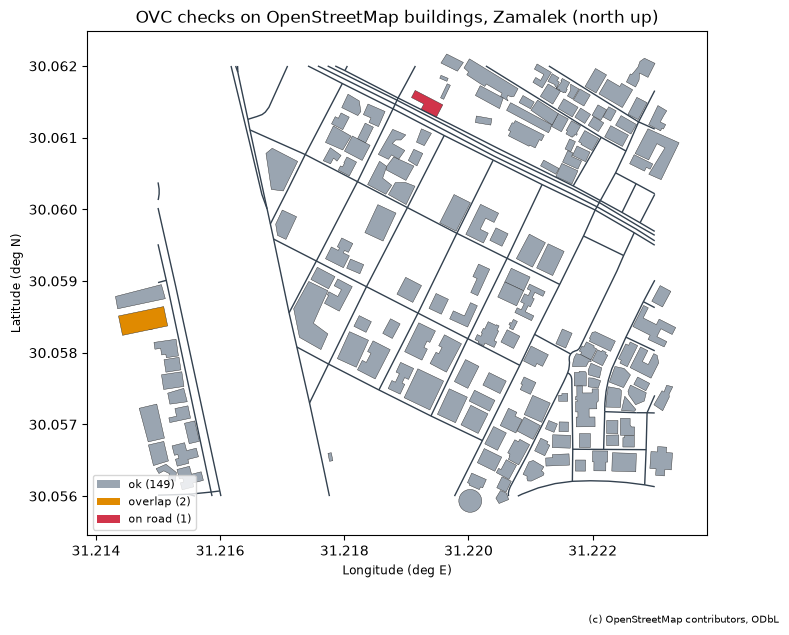

In [7]:
flag_overlap = set(overlaps['bldg_a']) | set(overlaps['bldg_b'])
flag_road = set(conflicts['bldg_id'])
def status(i):
    if i in flag_overlap and i in flag_road: return 'both'
    if i in flag_overlap: return 'overlap'
    if i in flag_road: return 'on road'
    return 'ok'
buildings['status'] = [status(i) for i in range(len(buildings))]
colors = {'ok': '#9aa5b1', 'overlap': '#e08a00', 'on road': '#d1344a', 'both': '#7a1fa2'}
fig, ax = plt.subplots(figsize=(8, 7))
roads.plot(ax=ax, color='#33414f', linewidth=1)
for s, col in colors.items():
    sub = buildings[buildings['status'] == s]
    if len(sub):
        sub.plot(ax=ax, facecolor=col, edgecolor='#2b2b2b', linewidth=0.3)
ax.legend(handles=[Patch(facecolor=col, label=f"{s} ({(buildings['status'] == s).sum()})")
                   for s, col in colors.items() if (buildings['status'] == s).any()],
          loc='lower left', fontsize=8)
ax.set_aspect(1 / 0.866)  # cos(30 deg) so metres look right on lon/lat axes
ax.set_xlabel('Longitude (deg E)'); ax.set_ylabel('Latitude (deg N)')
ax.set_title('OVC checks on OpenStreetMap buildings, Zamalek (north up)')
fig.text(0.99, 0.01, '(c) OpenStreetMap contributors, ODbL', ha='right', fontsize=7)
plt.show()